In [1]:
# Importing Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix
import seaborn as sns

In [3]:
### sklearn modules supply: 
# classification models (KNeighborsClassifier, SVC), 
# evaluation metrics (accuracy_score, classification_report), and 
# dataset splitting functions (train_test_split).

from sklearn import preprocessing
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn import model_selection
from sklearn.metrics import classification_report,accuracy_score
from sklearn.model_selection import train_test_split
from sklearn import model_selection

### Loading The Dataset

In [5]:
## The dataset is fetched directly from the UCI Machine Learning Repository.
url="https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/breast-cancer-wisconsin.data"

## Since the raw CSV file lacks a header row, explicit column names are defined via the names parameter to ensure readable attributes.
name=["id","clump_thickness","uniform_cell_size","uniform_cell_shape","marginal_adhesion","single_epithelial_size","bare_nuclei","bland_chromatin","normal_nucleoli","mitoses","class"]

df=pd.read_csv(url,names=name)

In [6]:
df.head()

,id,clump_thickness,uniform_cell_size,uniform_cell_shape,marginal_adhesion,single_epithelial_size,bare_nuclei,bland_chromatin,normal_nucleoli,mitoses,class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


In [7]:
## In the Breast Cancer Wisconsin dataset, missing records are represented as string '?' values (bare_nuclei feature). 
## Replacing '?' with -9999 flags missing data as an extreme outlier for tree/distance algorithms, preventing basic string operations from crashing.

df.replace('?',-9999,inplace=True)

,id,clump_thickness,uniform_cell_size,uniform_cell_shape,marginal_adhesion,single_epithelial_size,bare_nuclei,bland_chromatin,normal_nucleoli,mitoses,class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2
...,...,...,...,...,...,...,...,...,...,...,...
694,776715,3,1,1,1,3,2,1,1,1,2
695,841769,2,1,1,1,2,1,1,1,1,2
696,888820,5,10,10,3,7,3,8,10,2,4
697,897471,4,8,6,4,3,4,10,6,1,4


In [8]:
### Exploratory Data Inspection - 1
# df.info() checks data types and verifies row counts. (Note: bare_nuclei remains of type "object" due to string values before replacement).

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 699 entries, 0 to 698
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   id                      699 non-null    int64 
 1   clump_thickness         699 non-null    int64 
 2   uniform_cell_size       699 non-null    int64 
 3   uniform_cell_shape      699 non-null    int64 
 4   marginal_adhesion       699 non-null    int64 
 5   single_epithelial_size  699 non-null    int64 
 6   bare_nuclei             699 non-null    object
 7   bland_chromatin         699 non-null    int64 
 8   normal_nucleoli         699 non-null    int64 
 9   mitoses                 699 non-null    int64 
 10  class                   699 non-null    int64 
dtypes: int64(10), object(1)
memory usage: 60.2+ KB


In [9]:
### Exploratory Data Inspection - 2
# df.isnull().sum() verifies if standard Pandas NaN values exist.

df.isnull().sum()

id                        0
clump_thickness           0
uniform_cell_size         0
uniform_cell_shape        0
marginal_adhesion         0
single_epithelial_size    0
bare_nuclei               0
bland_chromatin           0
normal_nucleoli           0
mitoses                   0
class                     0
dtype: int64

In [10]:
### Exploratory Data Inspection - 3
# df.shape returns the dimensions (699, 11) — 699 samples/rows across 11 columns.

print(df.axes)
print(df.shape)

[RangeIndex(start=0, stop=699, step=1), Index(['id', 'clump_thickness', 'uniform_cell_size', 'uniform_cell_shape',
       'marginal_adhesion', 'single_epithelial_size', 'bare_nuclei',
       'bland_chromatin', 'normal_nucleoli', 'mitoses', 'class'],
      dtype='str')]
(699, 11)


In [11]:
### Feature Selection (Dropping the id Column):
# The id column is a unique identifier assigned to each patient. 
# Leaving id in the dataset would introduce noise or cause machine learning models to falsely memorize patient IDs rather than learning underlying clinical patterns.

df.drop(['id'],axis=1,inplace=True)

In [12]:
### Statistical Summary:
# df.describe() outputs key summary statistics (mean, standard deviation, min/max) for all numeric attributes.

print(df.shape)
df.describe()

(699, 10)


,clump_thickness,uniform_cell_size,uniform_cell_shape,marginal_adhesion,single_epithelial_size,bland_chromatin,normal_nucleoli,mitoses,class
count,699.000000,699.000000,699.000000,699.000000,699.000000,699.000000,699.000000,699.000000,699.000000
mean,4.417740,3.134478,3.207439,2.806867,3.216023,3.437768,2.866953,1.589413,2.689557
std,2.815741,3.051459,2.971913,2.855379,2.214300,2.438364,3.053634,1.715078,0.951273
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000
25%,2.000000,1.000000,1.000000,1.000000,2.000000,2.000000,1.000000,1.000000,2.000000
50%,4.000000,1.000000,1.000000,1.000000,2.000000,3.000000,1.000000,1.000000,2.000000
75%,6.000000,5.000000,5.000000,4.000000,4.000000,5.000000,4.000000,1.000000,4.000000
max,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,4.000000


In [13]:
# Visualizations

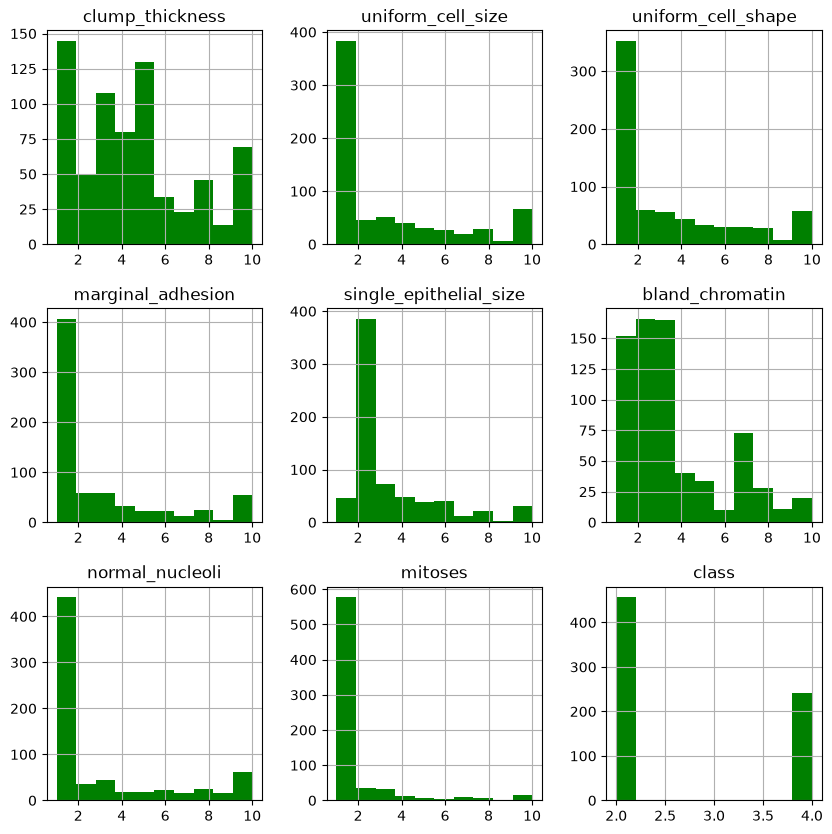

In [14]:
### Histogram Visualizations
# Plot Histograms for each Variable
# df.hist() plots individual distributions for each feature to check skewness, value ranges (most features range from 1 to 10) and 
# the distribution of target target classes (2 for benign, 4 for malignant).

df.hist(figsize=(10,10),color="green")
plt.show()

### Inference / Understanding from the Diagram:
# 1. Dominance of Low Severity Values (Right-Skewed Distributions)
# Features: uniform_cell_size, uniform_cell_shape, marginal_adhesion, single_epithelial_size, normal_nucleoli, and mitoses.
# Inference: 
#  A vast majority of the samples record values clustered near 1 or 2. 
#  This indicates that most patients in this dataset present normal, non-pathological tissue characteristics (small cell size, normal shape, minimal adhesion, low mitotic activity). 
#  Higher scores (ranging from 3 to 10) occur with much lower frequency.
#
# 2. Multi-Modal / Spread Distributions:
# Features: clump_thickness and bland_chromatin.
# Inference: 
#  Unlike the heavily skewed features, these show a wider distribution across values 1 through 5, with secondary peaks around values 5 and 7–8. 
#  This indicates higher variability in the dataset for these specific attributes, making them potentially strong indicators for differentiating between sample groups.
#
# 3. Class Imbalance (Target Variable):
# Feature: class (Bottom-right subplot).
# Inference:
#  Class values are strictly binary: 2 (Benign) and 4 (Malignant).
#  There are roughly 450 benign cases (~65%) compared to approximately 240 malignant cases (~35%).
#  The dataset is moderately imbalanced toward benign tumors, which should be considered when selecting model evaluation metrics (ex: looking at Precision/Recall rather than just Accuracy).
#
# 4. Bimodal Spike at Extreme Values:
# Observation: Several attributes (uniform_cell_size, uniform_cell_shape, marginal_adhesion, normal_nucleoli) display a minor secondary peak right at the maximum value of 10.
# Inference: When malignant tumors develop, their clinical indicators often jump straight to maximum severity levels rather than distributing evenly across intermediate values (3–9).
# 

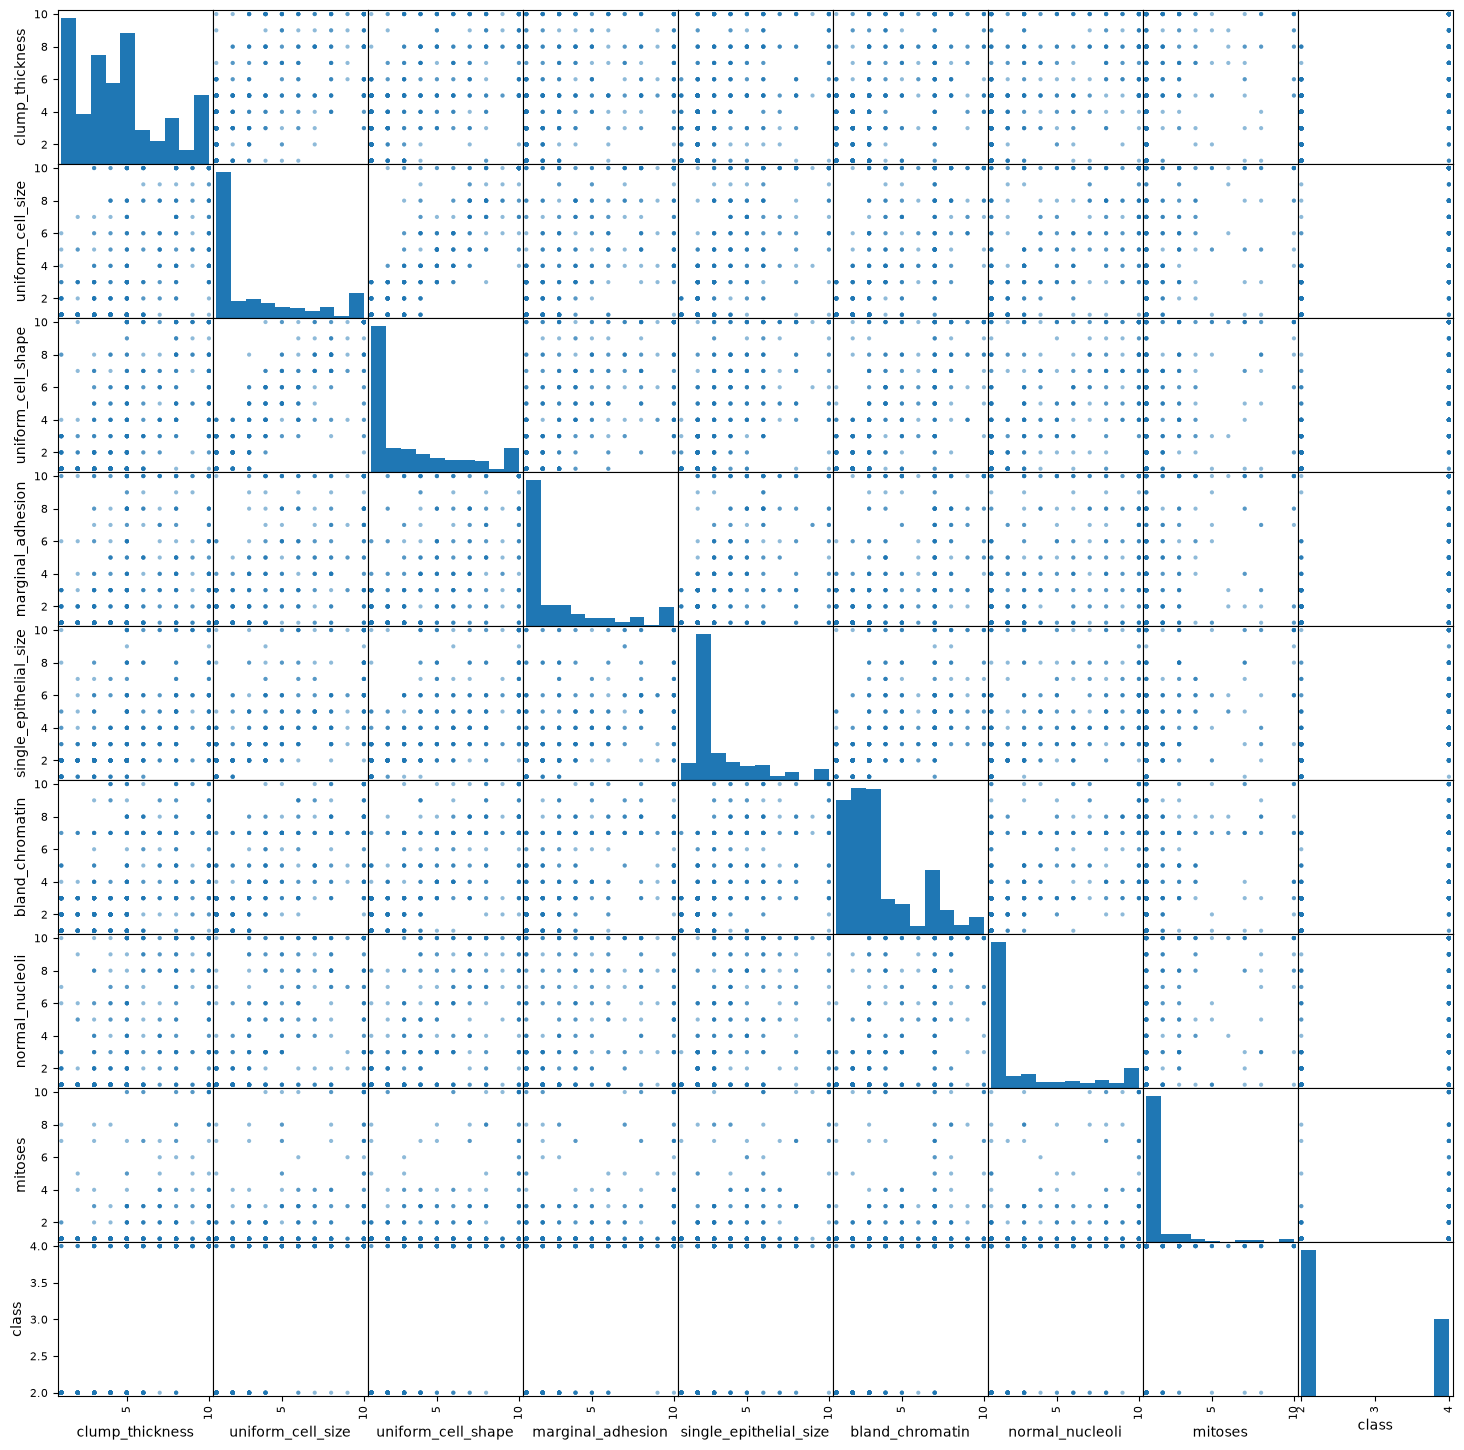

In [15]:
### Scatter plots - for comparing every numeric feature in df against every other numeric feature:
# Pairwise Feature Comparison: Generates a grid of scatter plots comparing every numeric feature in df against every other numeric feature.
# Distribution Plots: Along the main diagonal (where a feature is plotted against itself), it displays histograms or kernel density estimations showing the distribution of individual variables.
# Pattern Recognition: Helps visually identify correlations (linear or non-linear relationships), clusters, and potential outliers between features across the entire dataset.
# Size Customization: The figsize=(18,18) parameter ensures the resulting plot grid is large enough to comfortably read multi-feature comparisons without crowded or overlapping axis labels.

scatter_matrix(df,figsize=(18,18))
plt.show()

<Axes: >

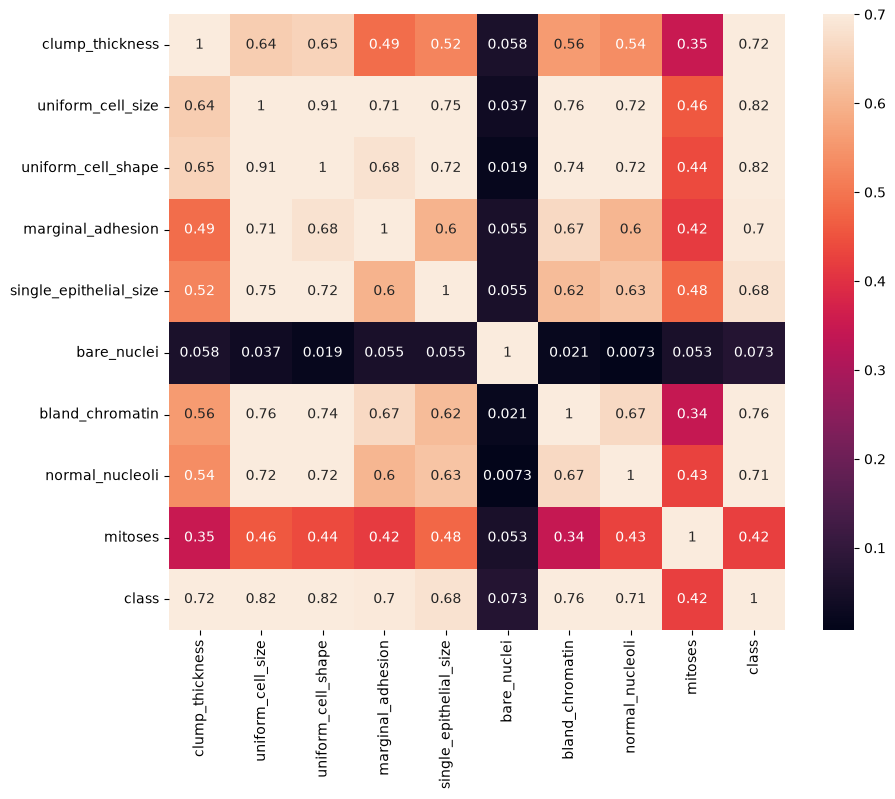

In [16]:
# Calculates pairwise Pearson correlation coefficients between all numerical features in the DataFrame df. 
# It produces a square correlation matrix where values range from -1.0 (perfect negative linear correlation) to +1.0 (perfect positive linear correlation), with 0 indicating no linear correlation.

crr=df.corr()


# Initializes Matplotlib figure (f) & axes object (ax) with a custom canvas size of 10 inches wide by 8 inches tall. creating adequate space to display heatmap without crowding text or axis labels.

f,ax=plt.subplots(figsize=(10,8))


# Renders the matrix as a visual color-coded heatmap using Seaborn with specific display settings:
# vmax=0.7: Sets the upper color intensity threshold to 0.7. Any correlation value of 0.7 or higher displays at maximum color saturation, helping highlight strong correlations more distinctly.
# square=True: Forces each cell in the grid to be rendered as a perfect square, maintaining symmetry.
# annot=True: Displays the exact numerical correlation values inside each cell.
# cbar=True: Renders a colorbar legend along the side to indicate how color tones map to correlation values.

sns.heatmap(crr,vmax=0.7,square=True,annot=True,cbar=True)

In [17]:
# Separating and Splitting Dataset

In [18]:
X=np.array(df.drop(['class'],axis=1))
y=np.array(df['class'])

In [19]:
type(X)

numpy.ndarray

In [20]:
print("Shape of X :",X.shape)
print("Shape of Y :",y.shape)
#print("Columns of X :",X.columns)

Shape of X : (699, 9)
Shape of Y : (699,)


In [21]:
type(X)

numpy.ndarray

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33)

In [23]:
# Specify Testing Options
seed=8
scog= 'accuracy'

In [24]:
models=[]
models.append(('KVM',KNeighborsClassifier(n_neighbors = 5)))
models.append(('SVM',SVC()))

results=[]
names=[]
for name,model in models:
    kfold= model_selection.KFold(n_splits=10,random_state=seed)
    print(kfold)
    cv_results=model_selection.cross_val_score(model,X_train,y_train,cv=kfold,scoring=scog)
    results.append(cv_results)
    names.append(name)
    msg= " {} {}  ({}) ".format(name,cv_results.mean(),cv_results.std())
    print(msg)
   #print(results)

ValueError: Setting a random_state has no effect since shuffle is False. You should leave random_state to its default (None), or set shuffle=True.

In [ ]:
for name,model in models:
    model.fit(X_train,y_train)
    pred= model.predict(X_test)
    print(name)
    print(accuracy_score(y_test,pred))
    print(classification_report(y_test,pred))